# Discharge reconstruction and flood-frequency analysis

GEO4300 project, Narsjø station 2.11.0.

Run the notebook from top to bottom. It uses the saved reconstruction and validation results by default, then recalculates the flood-frequency results and figures. Set `rerun_reconstruction = True` to repeat the reconstruction and matched validation from the original NVE and SMHI files. That option takes substantially longer.

The longer numerical routines are functions in `reconstruction.py`, `eva.py` and `plots.py`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image, display

import reconstruction
import eva
import plots
import checks

rerun_reconstruction = False
folder = Path.cwd()
output_folder = folder / "results"
output_folder.mkdir(exist_ok=True)

## Data and year selection

The record covers complete calendar years from 1987 to 2025 on an uninterrupted hourly UTC grid. NVE values require secondary quality control and correction code 0 or 1. NVE-excluded years are omitted from the analysis. Each Swedish hourly mean requires four approved 15-minute readings.

The reference contains 1994–1996, 2000 and 2015–2025. The 120-hour coverage screen initially retained 16 years. Manual review excluded 1997 because a rising-flow gap could conceal a flood peak, while retaining the two short low-flow gaps in 2019. Source files and station coordinates are listed below.

In [2]:
sources = pd.read_csv("data/sources.csv", dtype={"station_id": str})
display(sources[["station_id", "provider", "file"]])

if rerun_reconstruction:
    hourly, years, validation = reconstruction.reconstruct_all()
else:
    hourly, years, validation = reconstruction.read_reconstruction()

reference_years = reconstruction.reference_years
expanded_years = years.loc[years.included_after, "year"].tolist()
observed = hourly.observed_discharge_m3_s
threshold = observed.loc[hourly.baseline_year].quantile(0.98)

checks.check_record(hourly, years)
print(f"Reference years: {len(reference_years)}")
print(f"Expanded years: {len(expanded_years)}")
print(f"Common threshold: {threshold:.7f} m3/s")

,station_id,provider,file
0,2.11.0,NVE,2.11.0-Vannføring-time-v0.csv
1,2.265.0,NVE,2.265.0-Vannføring-time-v1.csv
2,2.11.0,NVE,2.11.0-Vannføring-dogn-v0.csv
3,1083,SMHI,smhi-opendata_2_1083_20261103_102644.csv
4,1223,SMHI,smhi-opendata_2_1223_20261103_102528.csv


Reference years: 15
Expanded years: 28
Common threshold: 12.8351426 m3/s


## Hourly reconstruction

Linear interpolation provides a constant-slope baseline. Donor regression uses one or two nearby gauges and selects lags by leave-one-year-out error. Each initial profile is also tested with a daily-mean constraint. The adjustment preserves observed hours and minimizes changes to the initial hourly rises and falls while matching the weighted daily totals.

Gap approvals require comparable validation periods, limits on hourly and peak errors, and additional event checks where a fill could affect flood selection. An unfilled gap can receive a separate low-flow risk assessment without inserting estimates into the hourly record.

In [3]:
eligible = ~years.year.isin(reconstruction.excluded_years)
missing_hours = int((years.loc[eligible, "calendar_hours"] - years.loc[eligible, "observed_hours"]).sum())
filled_hours = int(years.loc[eligible, "reconstructed_hours"].sum())
complete_years = int((years.included_after & years.remaining_hours.eq(0)).sum())

print(f"Reconstructed: {filled_hours:,} of {missing_hours:,} missing hours ({100 * filled_hours / missing_hours:.1f}%)")
print(f"Complete expanded years: {complete_years}")
display(years[["year", "observed_hours", "reconstructed_hours", "remaining_hours",
               "longest_remaining_gap_hours", "included_after", "reason"]])

Reconstructed: 20,077 of 23,796 missing hours (84.4%)
Complete expanded years: 27


,year,observed_hours,reconstructed_hours,remaining_hours,longest_remaining_gap_hours,included_after,reason
0,1987,8037,723,0,0,True,passed_coverage_and_event_checks
1,1988,8041,743,0,0,True,passed_coverage_and_event_checks
2,1989,6597,2163,0,0,True,passed_coverage_and_event_checks
3,1990,7260,1500,0,0,True,passed_coverage_and_event_checks
4,1991,8059,701,0,0,True,passed_coverage_and_event_checks
5,1992,8420,364,0,0,True,passed_coverage_and_event_checks
6,1993,0,0,8760,8760,False,nve_excluded
7,1994,8759,1,0,0,True,passed_coverage_and_event_checks
8,1995,8257,383,120,120,True,passed_coverage_and_event_checks
9,1996,8208,576,0,0,True,passed_coverage_and_event_checks


### May 2018 example

This test hides 24 hours from 11 May 2018 at 09:00 UTC. The measured discharge remains available as a reference for scoring. The donor fit excludes 2018, and daily means remain available as support information.

In [4]:
data = reconstruction.create_reconstruction()
first = data["index"].get_loc(pd.Timestamp("2018-05-11 09:00", tz="UTC"))
hidden = np.arange(first, first + 24)
measured = data["q"][hidden].copy()
original = data["q"].copy()
data["q"][hidden] = np.nan
predictions = reconstruction.predict(data, hidden, [(first, first + 24)], (2018,))
data["q"] = original

example = []
for method, prediction in predictions.items():
    estimated = prediction["values"]
    example.append({
        "Method": method,
        "Measured peak (m3/s)": measured.max(),
        "Estimated peak (m3/s)": estimated.max(),
        "Peak timing error (h)": int(estimated.argmax() - measured.argmax()),
        "Hourly MAE (m3/s)": np.abs(estimated - measured).mean(),
    })
display(pd.DataFrame(example).round(3))

,Method,Measured peak (m3/s),Estimated peak (m3/s),Peak timing error (h),Hourly MAE (m3/s)
0,linear,34.924,30.541,11,3.116
1,donor_ols,34.924,37.694,-1,3.047
2,daily_linear,34.924,34.245,1,0.418
3,daily_donor_ols,34.924,35.438,-1,0.309


### Matched flood and non-flood tests

The comparison uses the same 13 flood/non-flood pairs at 6, 24, 72 and 168 hours, with all four methods available in every case. Each donor fit excludes the test year. These tests describe performance under matched input availability and do not replace the gap-specific approval tests.

peak_error_pct  peak_error_m3_s  mae_m3_s
regime    hours method                                                    
Flood     6     daily_donor_ols           0.280            0.075     0.096
                daily_linear              0.219            0.051     0.081
                donor_ols                20.842            4.729     4.991
                linear                    0.741            0.187     0.231
          24    daily_donor_ols           0.789            0.214     0.309
                daily_linear              0.866            0.228     0.238
                donor_ols                19.574            4.441     4.437
                linear                    5.316            1.363     1.454
          72    daily_donor_ols           2.483            0.738     0.646
                daily_linear              2.480            0.648     0.462
                donor_ols                14.679            3.376     3.788
                linear                   21.949            5.997     4.413
          168   daily_donor_ols           2.400            0.691     0.486
                daily_linear              2.373            0.631     0.312
                donor_ols                14.221            3.376     2.502
                linear                   40.940           10.464     5.872
Non-flood 6     daily_donor_ols           0.599            0.015     0.009
                daily_linear              0.507            0.016     0.013
                donor_ols                19.231            0.328     0.365
                linear                    0.331            0.009     0.011
          24    daily_donor_ols           0.338            0.005     0.022
                daily_linear              0.267            0.007     0.021
                donor_ols                22.339            0.365     0.349
                linear                    0.234            0.008     0.028
          72    daily_donor_ols           0.931            0.024     0.025
                daily_linear              0.461            0.008     0.021
                donor_ols                24.792            0.393     0.335
                linear                    0.232            0.006     0.087
          168   daily_donor_ols           0.789            0.025     0.033
                daily_linear              0.446            0.027     0.025
                donor_ols                25.412            0.580     0.321
                linear                    1.321            0.033     0.301

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


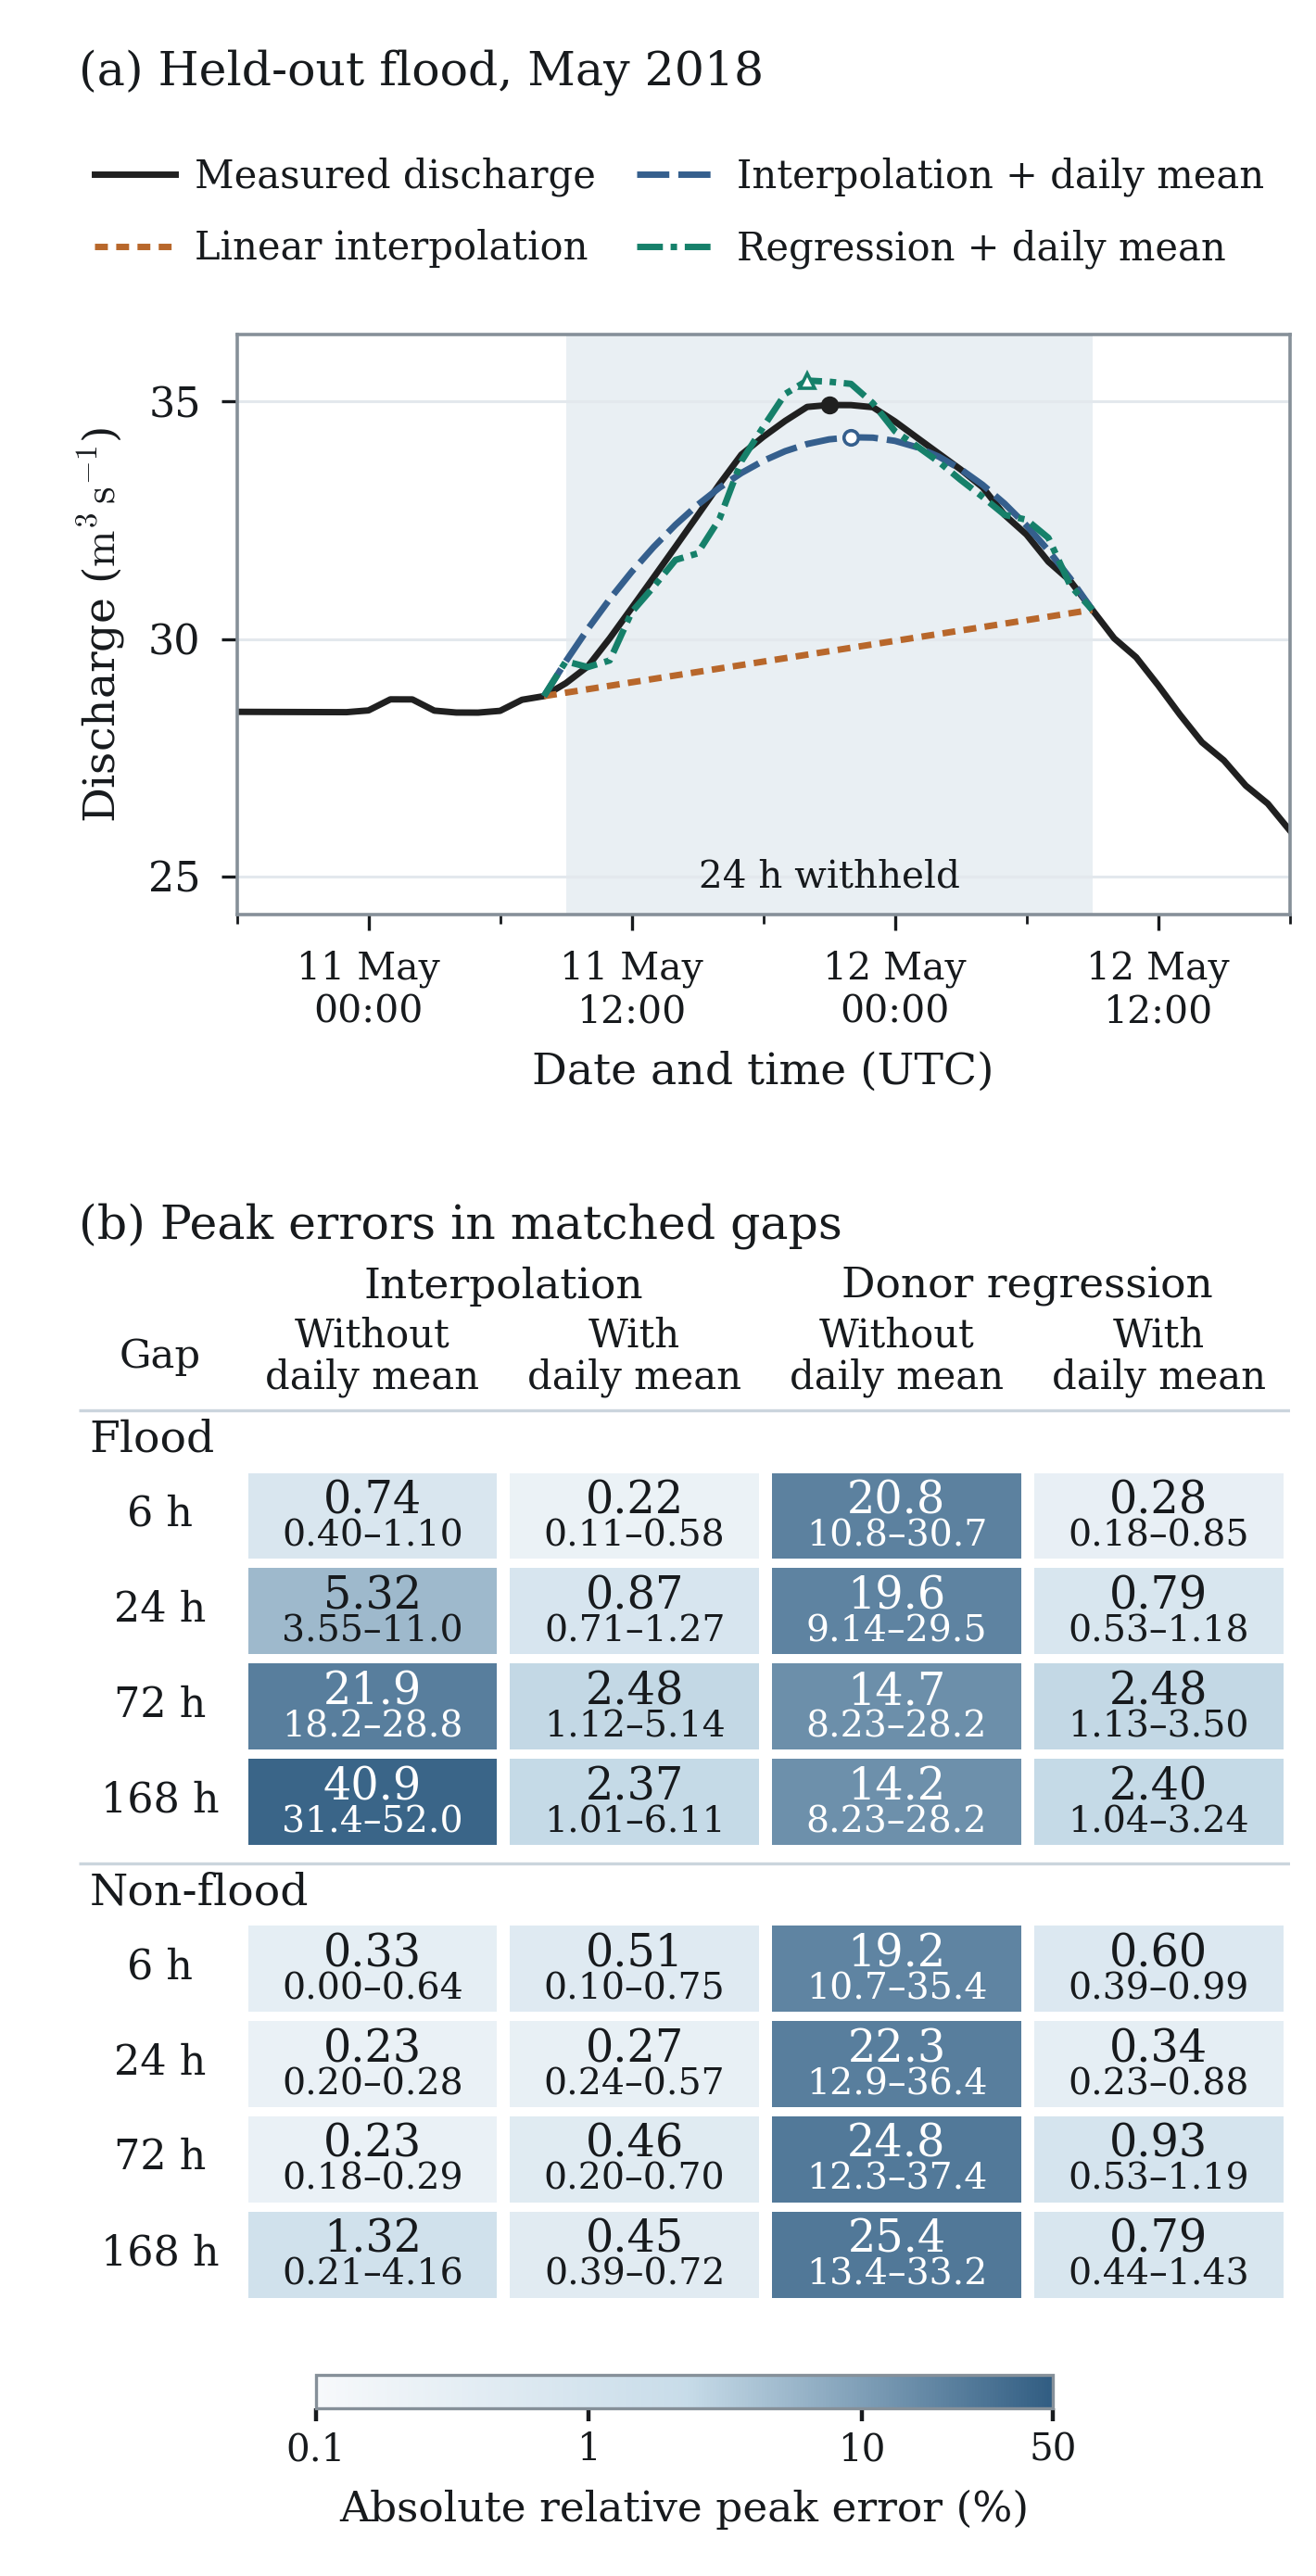

In [5]:
if rerun_reconstruction:
    errors, cases, profiles = reconstruction.run_matched_tests(expanded_years)
    saved_errors = pd.read_csv("data/processed/benchmark/matched_benchmark_errors.csv")
    fields = ["peak_error_pct", "peak_error_m3_s", "mae_m3_s", "mae_pct", "timing_error_h"]
    np.testing.assert_allclose(errors[fields], saved_errors[fields], rtol=1e-8, atol=1e-8)
else:
    errors = pd.read_csv("data/processed/benchmark/matched_benchmark_errors.csv")

checks.check_benchmark(errors)
comparison = errors.groupby(["regime", "hours", "method"])[["peak_error_pct", "peak_error_m3_s", "mae_m3_s"]].median()
display(comparison.round(3))
benchmark_folder = folder / ("results/benchmark" if rerun_reconstruction else "data/processed/benchmark")
plots.plot_reconstruction(benchmark_folder)
display(Image(filename="Figures/discharge_reconstruction.png"))

## Flood-event selection

The threshold is the 98th percentile of accepted reference observations and is fixed for both samples. Exceedances separated by at most 312 hours are grouped. Neighboring groups are merged unless the discharge between their peaks falls below two-thirds of the first peak. Events can cross New Year, and missing hours do not count as low discharge.

Validated estimates can establish event separation for measured reference peaks. They do not fill the reference record or add observation time. Annual exposure counts only available hourly values and uses 365.2425 days per year.

In [6]:
source_folder = folder / ("results/reconstruction" if rerun_reconstruction else "data/processed")
screens = pd.read_csv(source_folder / "gap_flood_risk_screens.csv")
reference_context = eva.reference_context(hourly, screens, threshold)
before_events, before_exposure = eva.select_events(
    hourly, reference_years, "observed_discharge_m3_s", threshold, reference_context
)
after_events, after_exposure = eva.select_events(
    hourly, expanded_years, "pot_discharge_m3_s", threshold,
    hourly.event_context_upper_m3_s.to_numpy()
)

for name, events, exposure in [("Reference", before_events, before_exposure),
                                ("Expanded", after_events, after_exposure)]:
    print(f"{name}: {len(events)} events over {exposure:.3f} years of available data")
    print(events.event_source.value_counts().to_string())

Reference: 16 events over 14.846 years of available data
event_source
fully_observed                          12
measured_peak_with_validated_context     4
Expanded: 34 events over 27.990 years of available data
event_source
fully_observed                          27
measured_peak_with_validated_context     7


## Extreme value analysis

The generalized Pareto distribution is fitted by maximum likelihood to peak excesses above the common threshold, with location fixed at zero. Return levels use the event rate per year of available data.

The 95% intervals come from 1,000 bootstrap samples of event peaks. Seeds 4300 and 4301 reproduce the reference and expanded calculations. The threshold, event rate and reconstructed series remain fixed, so the intervals are conditional on these choices.

The flood-probability examples assume independent years and fixed annual probabilities of 1/T. They depend on the time horizon, rather than on the discharge data. A separate common-year check holds the 15 reference years fixed.

In [7]:
summaries, levels, catalogs, bootstraps = [], [], [], {}
samples = [("before", before_events, before_exposure, 4300),
           ("after", after_events, after_exposure, 4301)]

for name, events, exposure, seed in samples:
    summary, estimates, draws = eva.fit_sample(events, exposure, threshold, seed=seed, samples=1000)
    summary["sample"] = name
    summary["n_years"] = len(reference_years) if name == "before" else len(expanded_years)
    estimates.insert(0, "sample", name)
    catalog = events.copy()
    catalog.insert(0, "sample", name)
    summaries.append(summary)
    levels.append(estimates)
    catalogs.append(catalog)
    bootstraps[name] = draws
    print(f"Completed {name} bootstrap")

summary = pd.DataFrame(summaries)
levels = pd.concat(levels, ignore_index=True)
events = pd.concat(catalogs, ignore_index=True)
checks.check_eva(summary, levels, events, bootstraps)
display(summary.set_index("sample").round(4))
display(levels.round(3))

periods = np.array([20, 200, 1000])
probabilities = pd.DataFrame({
    "Return period (years)": periods,
    "At least one exceedance in 15 years (%)": 100 * (1 - (1 - 1 / periods) ** 15),
    "At least one exceedance in 28 years (%)": 100 * (1 - (1 - 1 / periods) ** 28),
})
display(probabilities.round(1))

# Hold the calendar years fixed to examine the change in available observation time.
common_events = after_events.loc[after_events.peak_year.isin(reference_years)]
np.testing.assert_array_equal(common_events.peak_utc, before_events.peak_utc)
np.testing.assert_allclose(common_events.peak_m3_s, before_events.peak_m3_s)
common_exposure = hourly.loc[hourly.baseline_year, "pot_discharge_m3_s"].notna().sum() / (24 * 365.2425)
before_fit = summary.loc[summary["sample"].eq("before")].iloc[0]
common_levels = eva.return_levels(threshold, before_fit.gpd_shape, before_fit.gpd_scale,
                                 len(common_events) / common_exposure)
print(f"Same 15 years after reconstruction: {len(common_events)} measured peaks, "
      f"20-year return level {common_levels[0]:.3f} m3/s")


Completed before bootstrap


Completed after bootstrap


,events,exposure_years,events_per_exposure_year,threshold_m3_s,mean_peak_m3_s,sample_sd_peak_m3_s,skewness,gpd_shape,gpd_scale,n_years
sample,,,,,,,,,,
before,16,14.8461,1.0777,12.8351,22.3929,7.5930,0.9601,-0.3807,13.3269,15
after,34,27.9896,1.2147,12.8351,22.6181,7.1221,0.6573,-0.4708,14.4562,28


,sample,return_period_years,return_level_m3_s,lower_95_m3_s,upper_95_m3_s
0,before,20,36.964,25.471,40.502
1,before,200,43.312,25.641,55.467
2,before,1000,45.386,25.647,65.305
3,after,20,36.702,31.322,39.725
4,after,200,41.226,32.963,46.046
5,after,1000,42.454,33.218,50.284


,Return period (years),At least one exceedance in 15 years (%),At least one exceedance in 28 years (%)
0,20,53.7,76.2
1,200,7.2,13.1
2,1000,1.5,2.8


Same 15 years after reconstruction: 16 measured peaks, 20-year return level 36.924 m3/s


### Model diagnostics

The quantile plot compares observed excesses with the fitted GPD. A short sample gives limited information about the upper tail, especially for the 200- and 1000-year extrapolations.

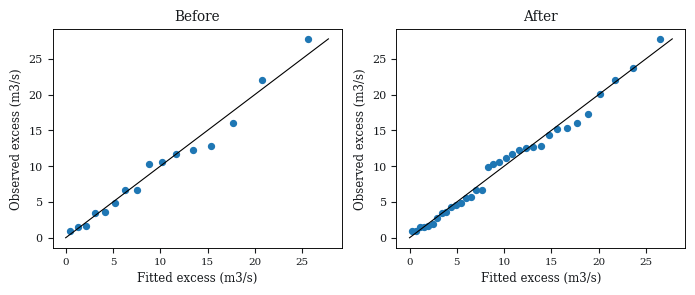

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, name, sample_events in zip(axes, ["before", "after"], [before_events, after_events]):
    fitted = summary.loc[summary["sample"].eq(name)].iloc[0]
    excess = np.sort(sample_events.peak_m3_s.to_numpy() - threshold)
    probabilities = (np.arange(1, len(excess) + 1) - 0.5) / len(excess)
    theoretical = stats.genpareto.ppf(probabilities, fitted.gpd_shape, scale=fitted.gpd_scale)
    ax.scatter(theoretical, excess, s=18)
    limit = max(theoretical.max(), excess.max())
    ax.plot([0, limit], [0, limit], color="black", linewidth=0.8)
    ax.set(title=name.capitalize(), xlabel="Fitted excess (m3/s)", ylabel="Observed excess (m3/s)")
fig.tight_layout()
plt.show()

## Figures and data export

The orange time-series segments identify reconstructed hours in the expanded sample. Blue and green identify measured discharge in the reference and additional years. All event peaks in the final samples are measured.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


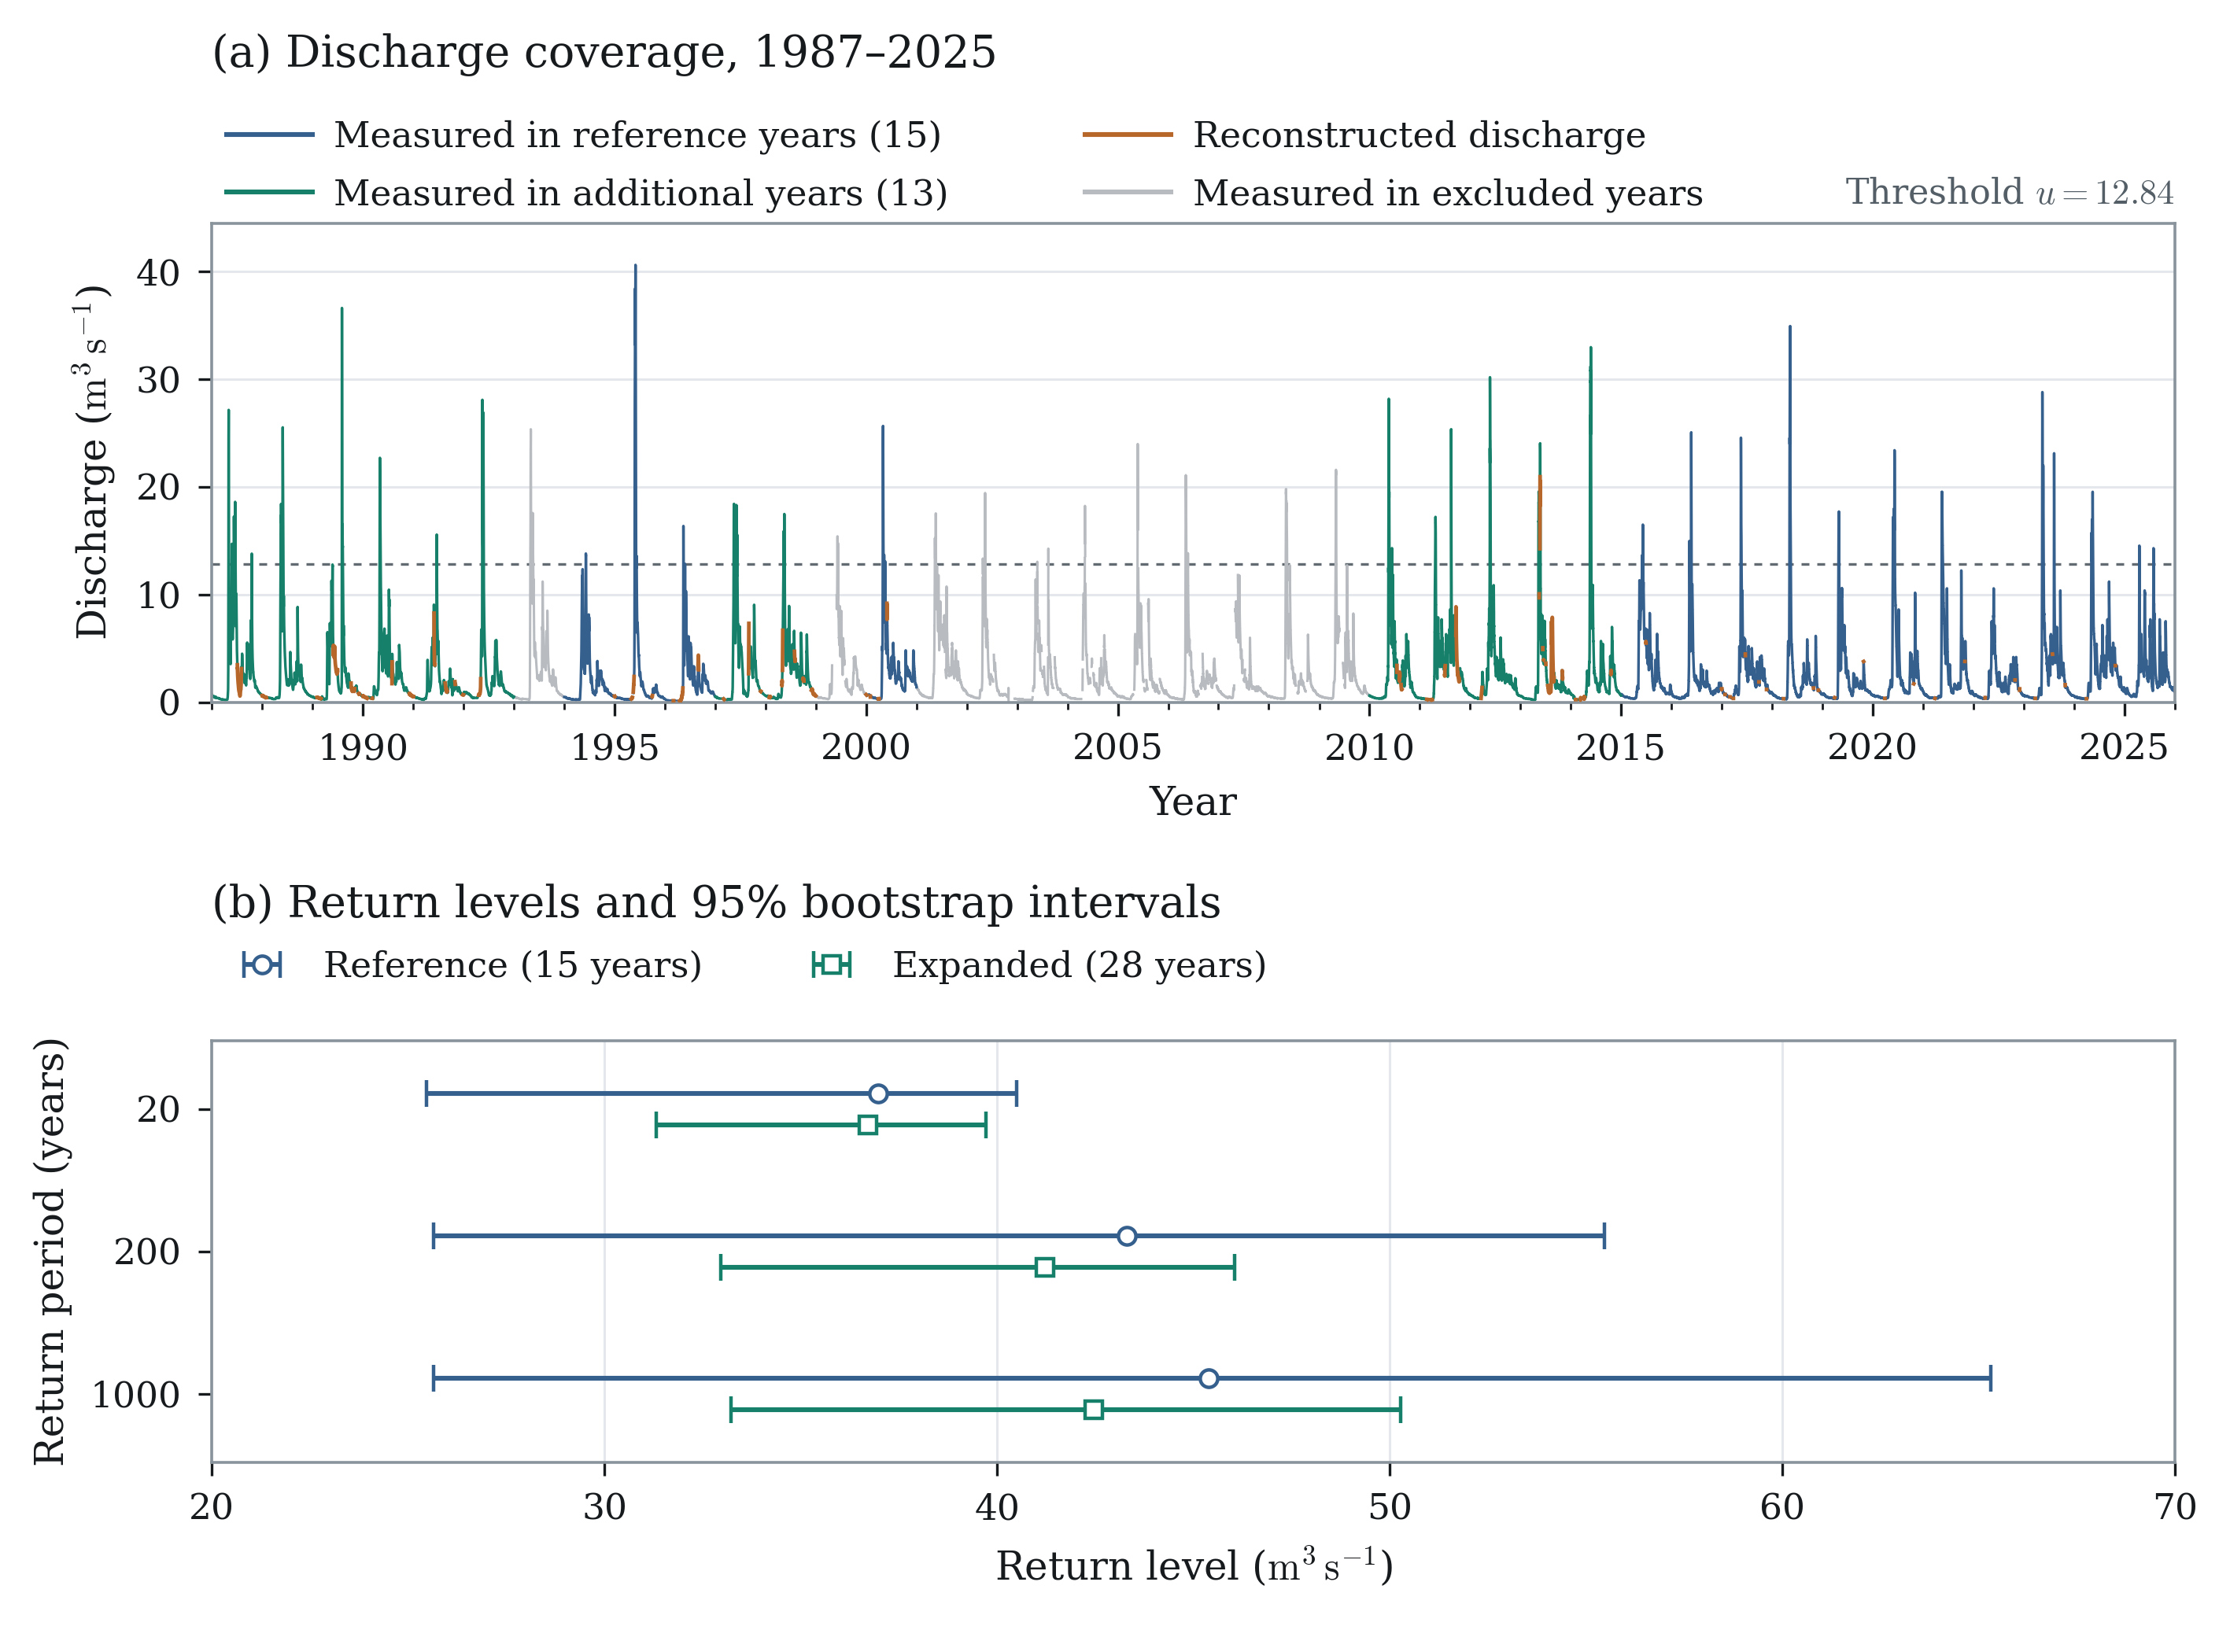

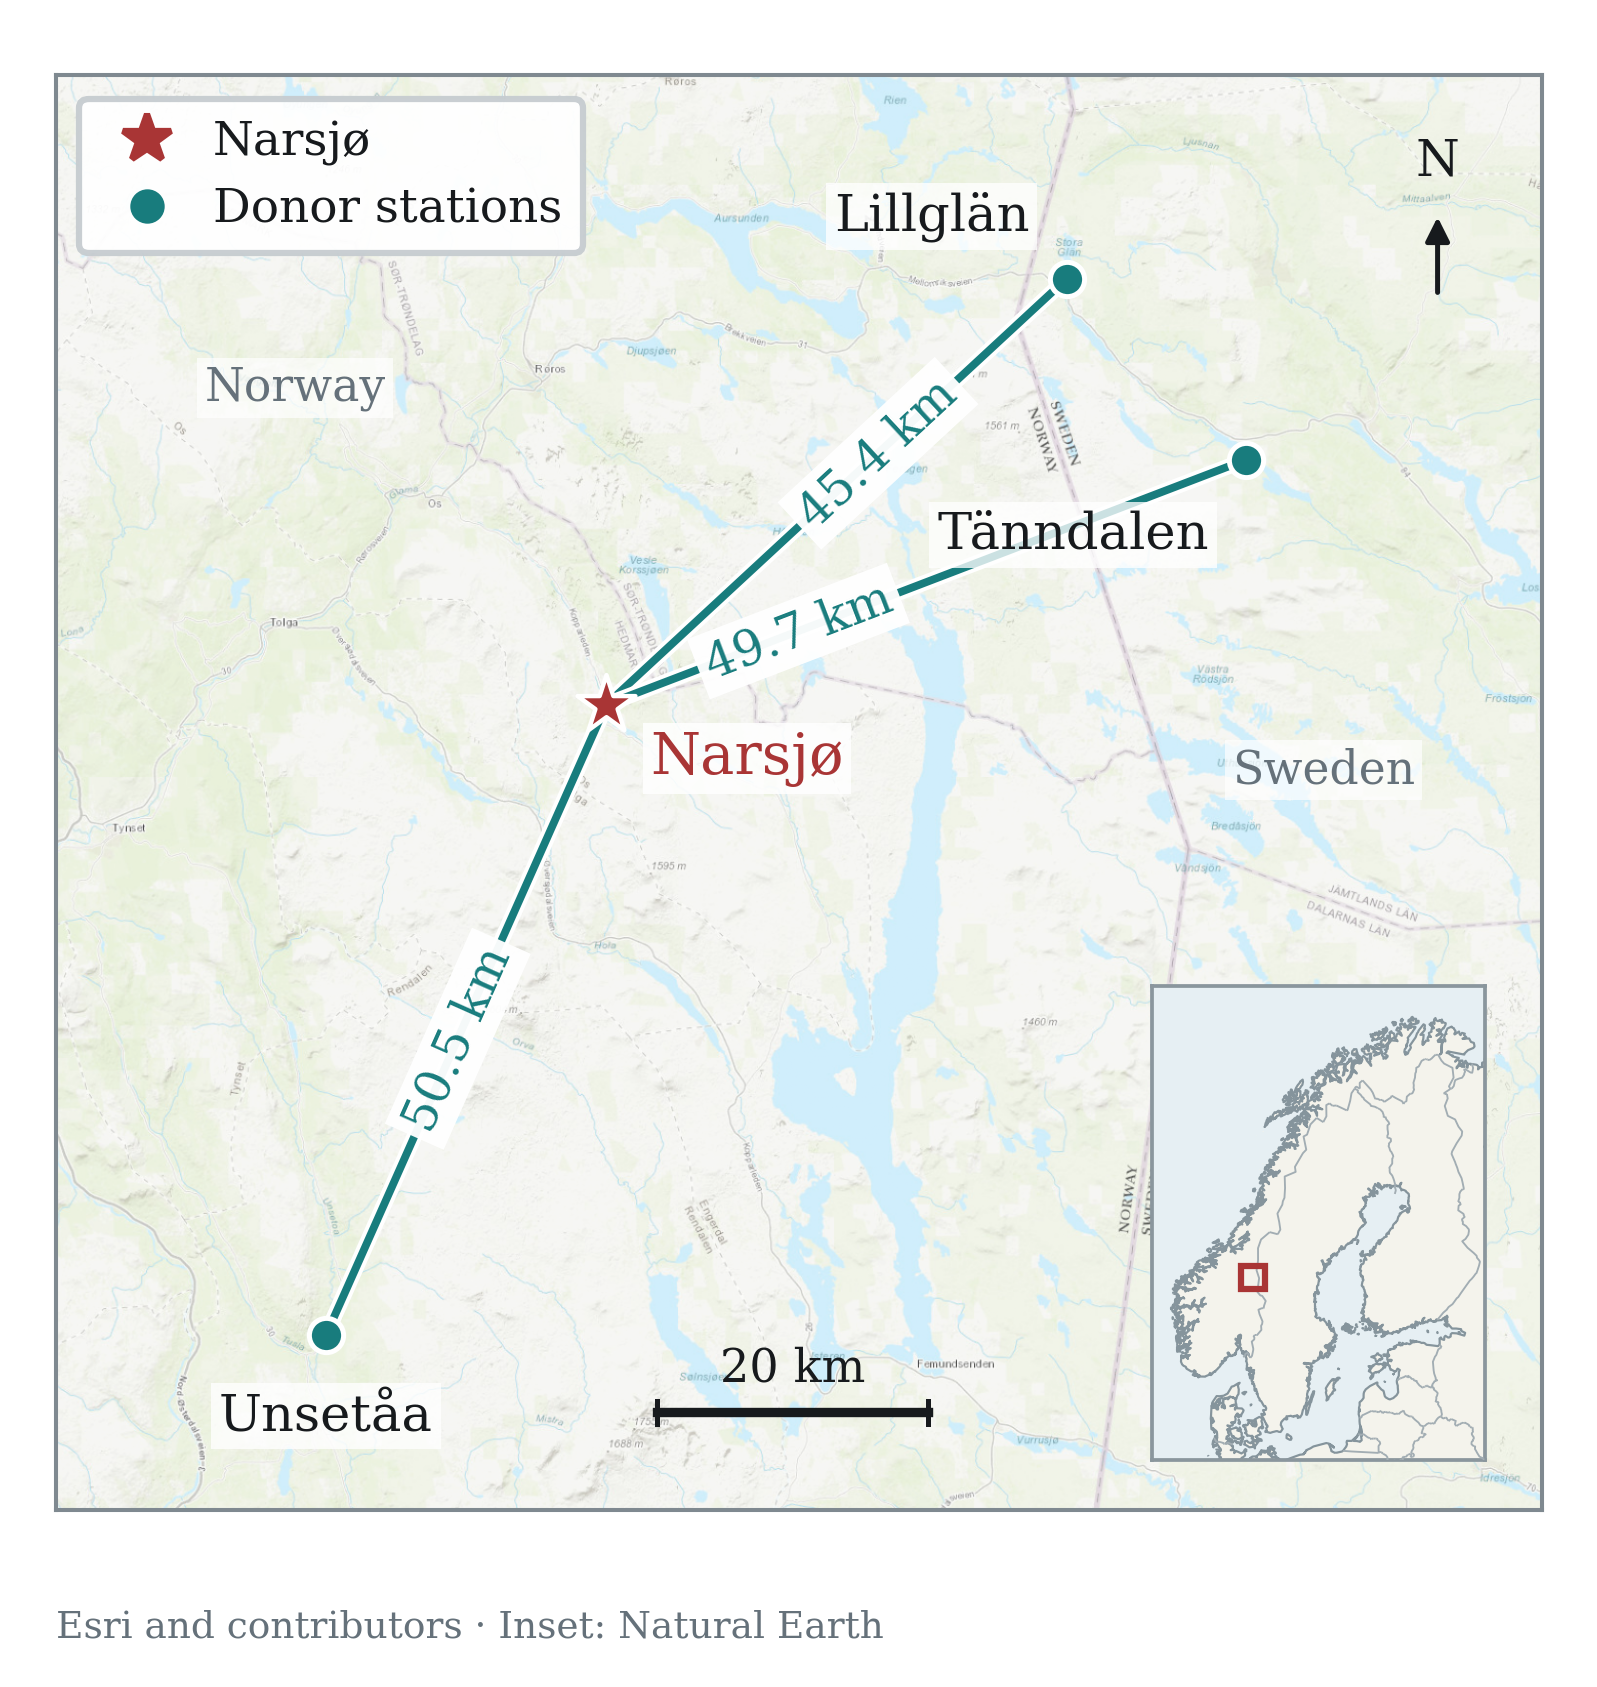

Figures and numerical exports saved. All checks passed.


In [9]:
plots.plot_flood_frequency(hourly, summary, levels, reference_years, expanded_years)
plots.plot_stations()
display(Image(filename="Figures/flood_frequency.png"))
display(Image(filename="Figures/station_map.png"))

summary.to_csv(output_folder / "eva_summary.csv", index=False)
levels.to_csv(output_folder / "return_levels.csv", index=False)
events.to_csv(output_folder / "events.csv", index=False)
for name, draws in bootstraps.items():
    draws.to_csv(output_folder / f"{name}_bootstrap.csv", index=False)

selected = hourly.loc[hourly.after_year_included, ["timestamp_utc", "pot_discharge_m3_s"]]
selected = selected.rename(columns={"pot_discharge_m3_s": "discharge_m3_s"})
selected.to_csv(output_folder / "narsjo_hourly.csv", index=False)
print("Figures and numerical exports saved. All checks passed.")